# Clasificación de hongos mediante Redes Neuronales Artificiales

Trabajo Práctico N° 2, Inteligencia Artificial, UTN FRBA. Grupo 9.

Se entrenan tres RNA heteroasociativas con aprendizaje supervisado offline por corrección de error para identificar el tipo de hongo a partir de una fotografía:

1. Perceptrón Multicapa con Back Propagation (modelo base).
2. Red Convolucional con una capa convolucional.
3. Red Convolucional con dos capas convolucionales.

El dataset original tiene 277 especies. Se trabaja con las 10 especies con más imágenes, para contar con suficientes ejemplos por clase.

Los datos se dividen de forma estratificada en entrenamiento (60%), validación (20%) y prueba (20%). La elección del modelo se hace únicamente con el conjunto de validación; el conjunto de prueba se usa recién al final, una vez tomada la decisión.

## 1. Librerías y configuración

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score

SEED = 42
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
MAX_EPOCAS = 40
NUM_CLASES_ELEGIDAS = 10
DIR_DATOS = "datos"
DIR_RESULTADOS = "resultados"

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
os.makedirs(DIR_RESULTADOS, exist_ok=True)

/root/tp2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


I0000 00:00:1792719837.576303     506 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## 2. Obtención y exploración de los datos

Se descarga el dataset *Mushroom Classification* de Kaggle y se arma una tabla con la ruta de cada imagen y su clase (el nombre de la carpeta que la contiene).

In [2]:
ruta_dataset = kagglehub.dataset_download("tinkhoav/mushroom-classification")

EXTENSIONES = (".jpg", ".jpeg", ".png")
registros = [
    {"ruta": os.path.join(raiz, archivo), "clase": os.path.basename(raiz)}
    for raiz, _, archivos in os.walk(ruta_dataset)
    for archivo in archivos
    if archivo.lower().endswith(EXTENSIONES)
]
df = pd.DataFrame(registros)
df = df.assign(archivo=df.ruta.map(os.path.basename)).drop_duplicates(subset=["clase", "archivo"])
print(f"Imágenes: {len(df)}  |  Clases: {df.clase.nunique()}")
df.clase.value_counts()

Imágenes: 83606  |  Clases: 277


clase
Stropharia_aeruginosa    444
Cortinarius_violaceus    429
Pholiota_limonella       404
Amanita_jacksonii        403
Pleurotus_pulmonarius    400
                        ... 
Pluteus_pellitus          48
Lactarius_musteus         37
Lactarius_utilis          28
Calocybe_persicolor       26
Russula_clavipes          24
Name: count, Length: 277, dtype: int64

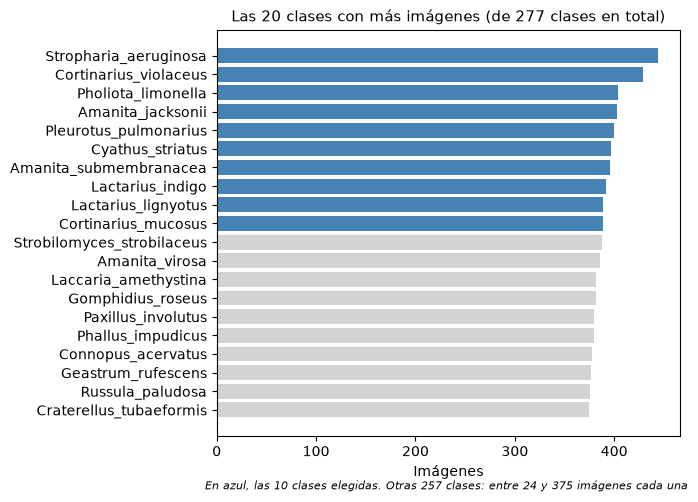

In [3]:
TOP_GRAFICO = 20
conteo = df.clase.value_counts()
top, resto = conteo.iloc[:TOP_GRAFICO], conteo.iloc[TOP_GRAFICO:]
colores = ["steelblue" if i < NUM_CLASES_ELEGIDAS else "lightgray" for i in range(len(top))]

plt.figure(figsize=(7, 5))
plt.barh(top.index[::-1], top.values[::-1], color=colores[::-1])
plt.title(f"Las {TOP_GRAFICO} clases con más imágenes (de {len(conteo)} clases en total)", fontsize=11)
plt.xlabel("Imágenes")
plt.figtext(0.99, 0.01, f"En azul, las {NUM_CLASES_ELEGIDAS} clases elegidas. "
            f"Otras {len(resto)} clases: entre {resto.min()} y {resto.max()} imágenes cada una",
            ha="right", fontsize=8, style="italic")
plt.tight_layout()
plt.savefig(f"{DIR_RESULTADOS}/distribucion_clases.png", dpi=120)
plt.show()

**Selección de clases.** Con 277 especies hay en promedio unas 300 imágenes por clase, insuficientes para entrenar desde cero una red que distinga diferencias tan finas. Se conservan las 10 especies con más imágenes; el criterio depende solo de la cantidad de ejemplos y se aplica antes de dividir los datos.

In [4]:
df = df[df.clase.isin(conteo.index[:NUM_CLASES_ELEGIDAS])]
print(f"Imágenes: {len(df)}  |  Clases: {df.clase.nunique()}")
df.clase.value_counts()

Imágenes: 4043  |  Clases: 10


clase
Stropharia_aeruginosa     444
Cortinarius_violaceus     429
Pholiota_limonella        404
Amanita_jacksonii         403
Pleurotus_pulmonarius     400
Cyathus_striatus          397
Amanita_submembranacea    396
Lactarius_indigo          392
Lactarius_lignyotus       389
Cortinarius_mucosus       389
Name: count, dtype: int64

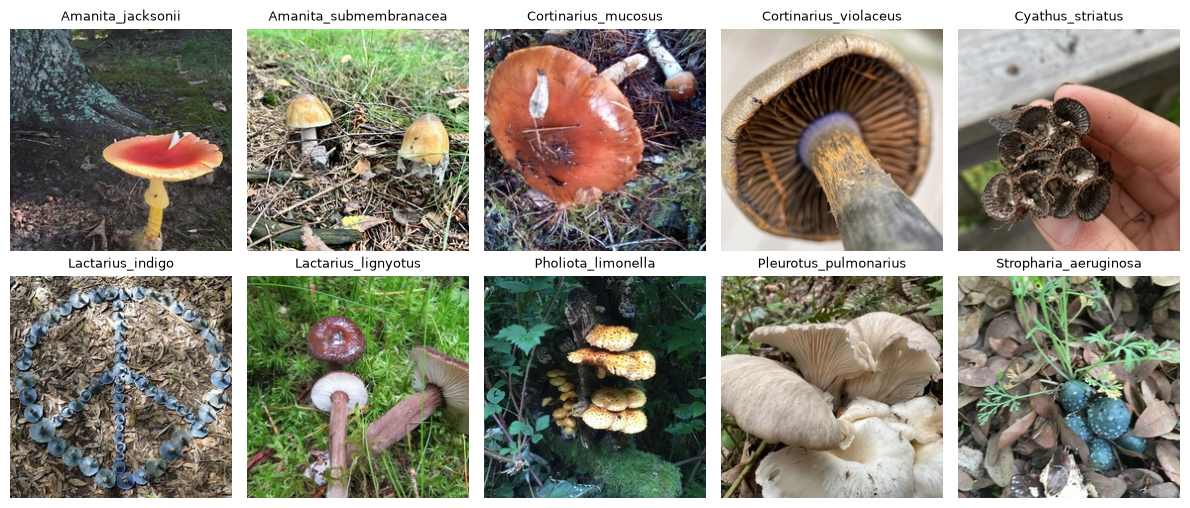

In [5]:
clases = sorted(df.clase.unique())
columnas = min(len(clases), 5)
filas = -(-len(clases) // columnas)
fig, ejes = plt.subplots(filas, columnas, figsize=(2.4 * columnas, 2.6 * filas), squeeze=False)
for eje in ejes.flat:
    eje.axis("off")
for eje, clase in zip(ejes.flat, clases):
    ruta = df[df.clase == clase].ruta.sample(1, random_state=SEED).iloc[0]
    eje.imshow(keras.utils.load_img(ruta))
    eje.set_title(clase, fontsize=9)
plt.tight_layout()
plt.savefig(f"{DIR_RESULTADOS}/ejemplos.png", dpi=120)
plt.show()

## 3. Preparación de los datos

**División estratificada.** Se separa primero el 20% para prueba y luego, del resto, el 25% para validación. Así quedan 60/20/20 manteniendo la proporción de cada clase en los tres conjuntos.

In [6]:
df_resto, df_prueba = train_test_split(df, test_size=0.20, stratify=df.clase, random_state=SEED)
df_entrenamiento, df_validacion = train_test_split(df_resto, test_size=0.25, stratify=df_resto.clase, random_state=SEED)

conjuntos = {"entrenamiento": df_entrenamiento, "validacion": df_validacion, "prueba": df_prueba}
pd.DataFrame({nombre: d.clase.value_counts() for nombre, d in conjuntos.items()}).assign(
    total=lambda t: t.sum(axis=1)
)

,entrenamiento,validacion,prueba,total
clase,,,,
Amanita_jacksonii,241,81,81,403
Amanita_submembranacea,238,79,79,396
Cortinarius_mucosus,233,78,78,389
Cortinarius_violaceus,257,86,86,429
Cyathus_striatus,239,79,79,397
Lactarius_indigo,236,78,78,392
Lactarius_lignyotus,233,78,78,389
Pholiota_limonella,242,81,81,404
Pleurotus_pulmonarius,240,80,80,400


**Reescalado.** Cada imagen se lleva a 128 x 128 píxeles en RGB y se guarda como JPG en una carpeta por clase dentro de cada conjunto. Esta estructura es la que se usa para entrenar y la que se publica en el repositorio. Las imágenes que no se pueden abrir se descartan.

In [7]:
import shutil
shutil.rmtree(DIR_DATOS, ignore_errors=True)
descartadas = 0
for nombre, d in conjuntos.items():
    for ruta, clase in zip(d.ruta, d.clase):
        destino = os.path.join(DIR_DATOS, nombre, clase)
        os.makedirs(destino, exist_ok=True)
        try:
            imagen = keras.utils.load_img(ruta, target_size=IMG_SIZE)
        except Exception:
            descartadas += 1
            continue
        archivo = os.path.splitext(os.path.basename(ruta))[0] + ".jpg"
        imagen.save(os.path.join(destino, archivo), quality=95)
print("Imágenes descartadas:", descartadas)

Imágenes descartadas: 0


In [8]:
def cargar(nombre, mezclar):
    return keras.utils.image_dataset_from_directory(
        os.path.join(DIR_DATOS, nombre), image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        shuffle=mezclar, seed=SEED,
    )

ds_entrenamiento = cargar("entrenamiento", mezclar=True)
ds_validacion = cargar("validacion", mezclar=False)
ds_prueba = cargar("prueba", mezclar=False)
CLASES = ds_entrenamiento.class_names
NUM_CLASES = len(CLASES)

Found 2425 files belonging to 10 classes.


I0000 00:00:1792719851.759439     506 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 9709 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3060, pci bus id: 0000:08:00.0, compute capability: 8.6


Found 809 files belonging to 10 classes.


Found 809 files belonging to 10 classes.


**Normalización.** Los valores de los píxeles se llevan al rango [0, 1] (Min-Max Scaler) con una capa `Rescaling(1/255)` al inicio de cada red, de modo que se aplica la misma normalización a los tres conjuntos.

## 4. Funciones de entrenamiento y evaluación

Todas las redes usan salida Softmax con una neurona por clase, entropía cruzada como función de error, optimizador Adam y entrenamiento por Mini-Batch. La cantidad de épocas se define con parada temprana: el entrenamiento se detiene cuando el error de validación deja de mejorar durante 5 épocas y se conservan los pesos de la mejor época.

In [9]:
def entrenar(modelo, tasa_aprendizaje):
    modelo.compile(
        optimizer=keras.optimizers.Adam(tasa_aprendizaje),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)
    historia = modelo.fit(ds_entrenamiento, validation_data=ds_validacion, epochs=MAX_EPOCAS, callbacks=[parada], verbose=2)
    return historia.history


def graficar_loss(historia, titulo, archivo):
    epocas = range(1, len(historia["loss"]) + 1)
    plt.figure(figsize=(6, 3.4))
    plt.plot(epocas, historia["loss"], label="Entrenamiento")
    plt.plot(epocas, historia["val_loss"], label="Validación", linestyle="--")
    plt.title(f"Error General (Loss) - {titulo}")
    plt.xlabel("Época")
    plt.ylabel("Entropía cruzada")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{DIR_RESULTADOS}/{archivo}.png", dpi=120)
    plt.show()


def predecir(modelo, ds):
    y_real, y_pred = [], []
    for x, y in ds:
        y_real.append(y.numpy())
        y_pred.append(modelo.predict_on_batch(x).argmax(axis=1))
    return np.concatenate(y_real), np.concatenate(y_pred)


def resumen(modelo, ds):
    y_real, y_pred = predecir(modelo, ds)
    _, _, f1, _ = precision_recall_fscore_support(y_real, y_pred, average="macro", zero_division=0)
    return {"exactitud": accuracy_score(y_real, y_pred), "f1_macro": f1}


def abreviar(clase):
    genero, especie = clase.split("_", 1)
    return f"{genero[0]}. {especie}"


def evaluar(modelo, ds, titulo, archivo):
    y_real, y_pred = predecir(modelo, ds)
    matriz = confusion_matrix(y_real, y_pred, labels=range(NUM_CLASES))
    precision, recuperacion, _, _ = precision_recall_fscore_support(
        y_real, y_pred, labels=range(NUM_CLASES), zero_division=0
    )
    etiquetas = [abreviar(c) for c in CLASES]
    metricas = pd.DataFrame({"Precisión": precision * 100, "Recuperación": recuperacion * 100}, index=etiquetas)

    fig, (eje_mc, eje_pr) = plt.subplots(1, 2, figsize=(7.2, 4.8), gridspec_kw={"width_ratios": [10, 2.4]})
    sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"fontsize": 8},
                xticklabels=etiquetas, yticklabels=etiquetas, ax=eje_mc)
    eje_mc.set_xlabel("Clase predicha", fontsize=9)
    eje_mc.set_ylabel("Clase real", fontsize=9)
    eje_mc.set_title("Matriz de confusión", fontsize=9)
    eje_mc.tick_params(labelsize=8)
    plt.setp(eje_mc.get_xticklabels(), rotation=45, ha="right")
    sns.heatmap(metricas, annot=True, fmt=".1f", cmap="Greens", vmin=0, vmax=100, cbar=False,
                annot_kws={"fontsize": 8}, yticklabels=False, ax=eje_pr)
    eje_pr.set_title("Precisión y\nRecuperación (%)", fontsize=9)
    eje_pr.tick_params(labelsize=8)
    plt.setp(eje_pr.get_xticklabels(), rotation=45, ha="right")
    fig.suptitle(f"{titulo} - Exactitud: {accuracy_score(y_real, y_pred):.1%}", fontsize=10)
    plt.tight_layout()
    plt.savefig(f"{DIR_RESULTADOS}/{archivo}.png", dpi=120)
    plt.show()

## 5. Entrenamiento 1: Perceptrón Multicapa con Back Propagation

La imagen se aplana en un vector (capa de entrada de 128 x 128 x 3 = 49.152 neuronas), seguida de dos capas ocultas totalmente conectadas con ReLU y la capa de salida Softmax. Sirve como modelo base: al recibir los píxeles como vector pierde la estructura espacial de la imagen.

In [10]:
mlp = keras.Sequential([
    keras.Input(shape=IMG_SIZE + (3,)),
    layers.Rescaling(1 / 255),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASES, activation="softmax"),
], name="MLP_BP")
mlp.summary()
historia_mlp = entrenar(mlp, tasa_aprendizaje=1e-4)

Model: "MLP_BP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    12,583,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,617,354 (48.13 MB)

 Trainable params: 12,617,354 (48.13 MB)

 Non-trainable params: 0 (0.00 B)

...

76/76 - 2s - 31ms/step - accuracy: 0.6932 - loss: 1.0072 - val_accuracy: 0.3671 - val_loss: 1.8191


Epoch 13/40


76/76 - 2s - 31ms/step - accuracy: 0.7229 - loss: 0.9495 - val_accuracy: 0.3523 - val_loss: 1.7725


Epoch 14/40


76/76 - 2s - 30ms/step - accuracy: 0.7348 - loss: 0.9027 - val_accuracy: 0.3659 - val_loss: 1.8813


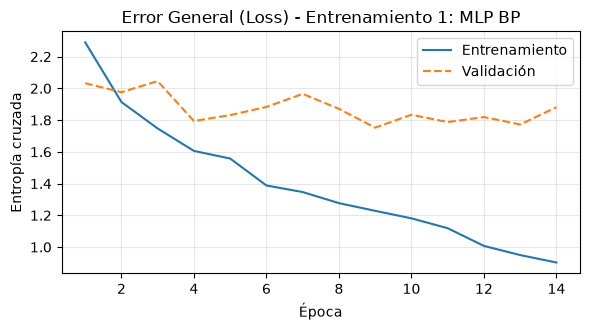

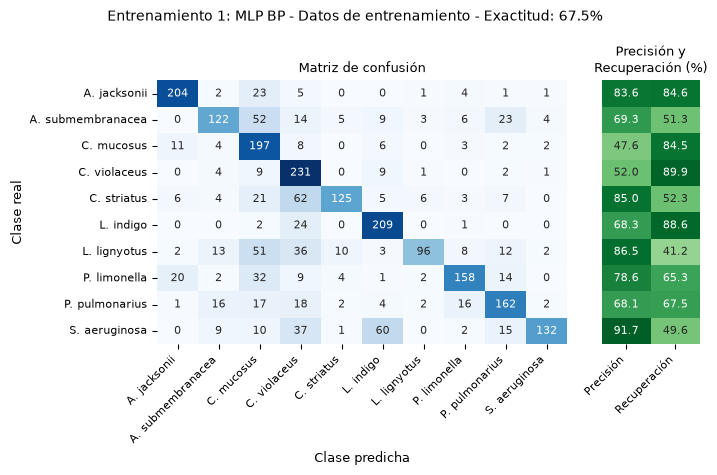

In [11]:
graficar_loss(historia_mlp, "Entrenamiento 1: MLP BP", "loss_mlp")
evaluar(mlp, ds_entrenamiento, "Entrenamiento 1: MLP BP - Datos de entrenamiento", "mc_mlp_entrenamiento")

## 6. Entrenamiento 2: Red Convolucional con una capa convolucional

Una capa convolucional (convolución con 32 filtros de 3 x 3, detector ReLU y Max Pooling de 2 x 2), la capa de aplanado (Reshape de matriz a vector), una capa lineal de 128 neuronas y la salida Softmax.

In [12]:
cnn1 = keras.Sequential([
    keras.Input(shape=IMG_SIZE + (3,)),
    layers.Rescaling(1 / 255),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASES, activation="softmax"),
], name="CNN_1_capa")
cnn1.summary()
historia_cnn1 = entrenar(cnn1, tasa_aprendizaje=1e-4)

Model: "CNN_1_capa"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 127008)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │    16,257,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,259,338 (62.02 MB)

 Trainable params: 16,259,338 (62.02 MB)

 Non-trainable params: 0 (0.00 B)

...

76/76 - 2s - 29ms/step - accuracy: 0.9410 - loss: 0.4013 - val_accuracy: 0.4957 - val_loss: 1.4975


Epoch 23/40


76/76 - 2s - 29ms/step - accuracy: 0.9493 - loss: 0.3775 - val_accuracy: 0.4796 - val_loss: 1.5320


Epoch 24/40


76/76 - 2s - 30ms/step - accuracy: 0.9489 - loss: 0.3499 - val_accuracy: 0.5056 - val_loss: 1.5144


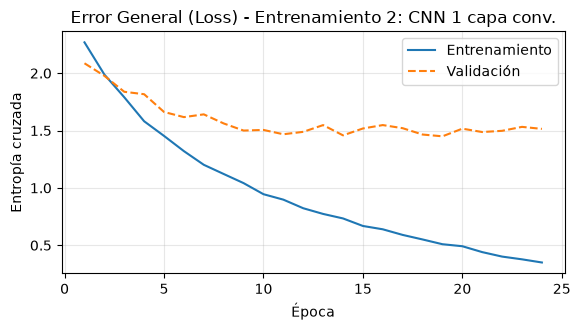

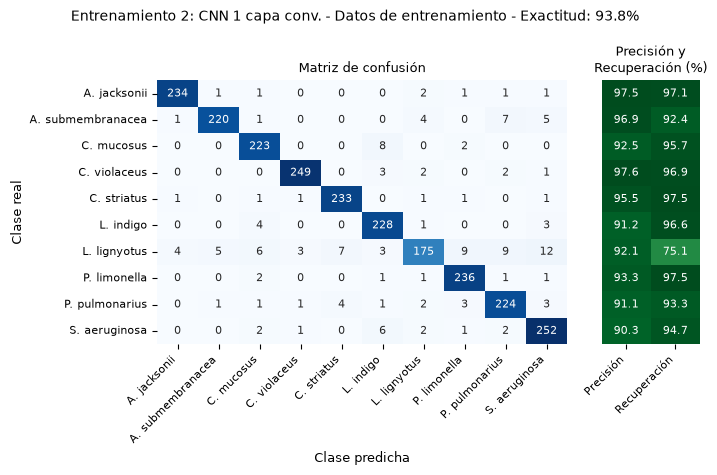

In [13]:
graficar_loss(historia_cnn1, "Entrenamiento 2: CNN 1 capa conv.", "loss_cnn1")
evaluar(cnn1, ds_entrenamiento, "Entrenamiento 2: CNN 1 capa conv. - Datos de entrenamiento", "mc_cnn1_entrenamiento")

## 7. Entrenamiento 3: Red Convolucional con dos capas convolucionales

Dos capas convolucionales sucesivas (64 y 32 filtros de 3 x 3, cada una con ReLU y Max Pooling de 2 x 2), aplanado, una capa lineal de 128 neuronas y la salida Softmax. La segunda capa convolucional trabaja sobre los mapas de características de la primera, lo que permite combinar bordes y colores en texturas y formas.

In [14]:
cnn2 = keras.Sequential([
    keras.Input(shape=IMG_SIZE + (3,)),
    layers.Rescaling(1 / 255),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(NUM_CLASES, activation="softmax"),
], name="CNN_2_capas")
cnn2.summary()
historia_cnn2 = entrenar(cnn2, tasa_aprendizaje=1e-4)

Model: "CNN_2_capas"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 126, 126, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 63, 63, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 61, 61, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 28800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │     3,686,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,708,074 (14.15 MB)

 Trainable params: 3,708,074 (14.15 MB)

 Non-trainable params: 0 (0.00 B)

...

76/76 - 2s - 31ms/step - accuracy: 0.8260 - loss: 0.6307 - val_accuracy: 0.5439 - val_loss: 1.3881


Epoch 14/40


76/76 - 2s - 32ms/step - accuracy: 0.8590 - loss: 0.5428 - val_accuracy: 0.5241 - val_loss: 1.4675


Epoch 15/40


76/76 - 2s - 30ms/step - accuracy: 0.8833 - loss: 0.4799 - val_accuracy: 0.5204 - val_loss: 1.4733


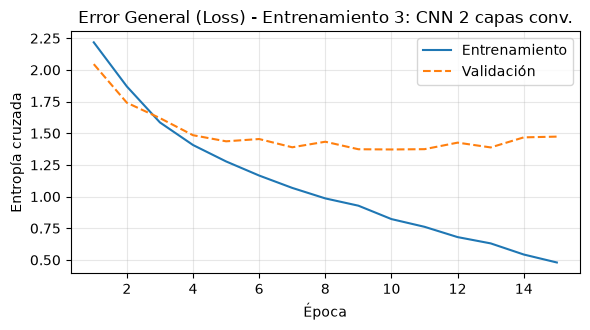

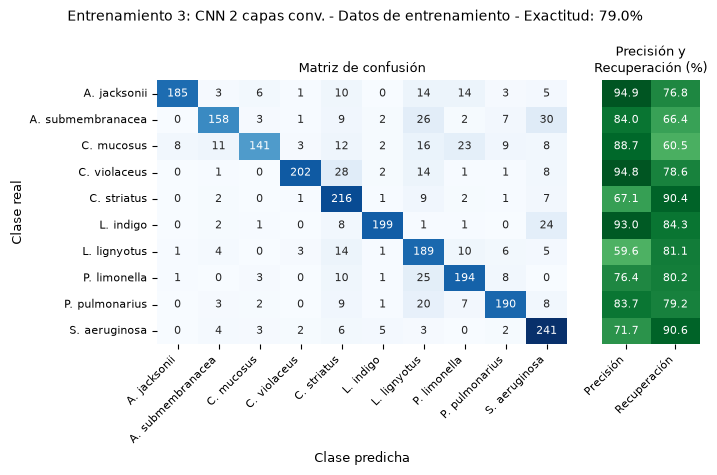

In [15]:
graficar_loss(historia_cnn2, "Entrenamiento 3: CNN 2 capas conv.", "loss_cnn2")
evaluar(cnn2, ds_entrenamiento, "Entrenamiento 3: CNN 2 capas conv. - Datos de entrenamiento", "mc_cnn2_entrenamiento")

## 8. Selección del modelo (conjunto de validación)

La decisión se toma comparando la exactitud y el F1 macro sobre validación. El conjunto de prueba todavía no se utilizó.

In [16]:
modelos = {"MLP BP": mlp, "CNN 1 capa conv.": cnn1, "CNN 2 capas conv.": cnn2}
historias = {"MLP BP": historia_mlp, "CNN 1 capa conv.": historia_cnn1, "CNN 2 capas conv.": historia_cnn2}

comparacion = pd.DataFrame({
    nombre: {
        "épocas": len(historias[nombre]["loss"]),
        "parámetros": modelo.count_params(),
        **{f"{k} entrenamiento": v for k, v in resumen(modelo, ds_entrenamiento).items()},
        **{f"{k} validación": v for k, v in resumen(modelo, ds_validacion).items()},
    }
    for nombre, modelo in modelos.items()
}).T
modelo_elegido = comparacion["f1_macro validación"].astype(float).idxmax()
print("Modelo elegido:", modelo_elegido)
comparacion.round(3)

Modelo elegido: CNN 2 capas conv.


,épocas,parámetros,exactitud entrenamiento,f1_macro entrenamiento,exactitud validación,f1_macro validación
MLP BP,14.0,12617354.0,0.675,0.671,0.375,0.346
CNN 1 capa conv.,24.0,16259338.0,0.938,0.936,0.519,0.518
CNN 2 capas conv.,15.0,3708074.0,0.790,0.791,0.543,0.544


## 9. Evaluación final con el conjunto de prueba

Con la decisión ya tomada, se ejecutan las tres redes sobre el conjunto de prueba para reportar su desempeño sobre datos nunca vistos.

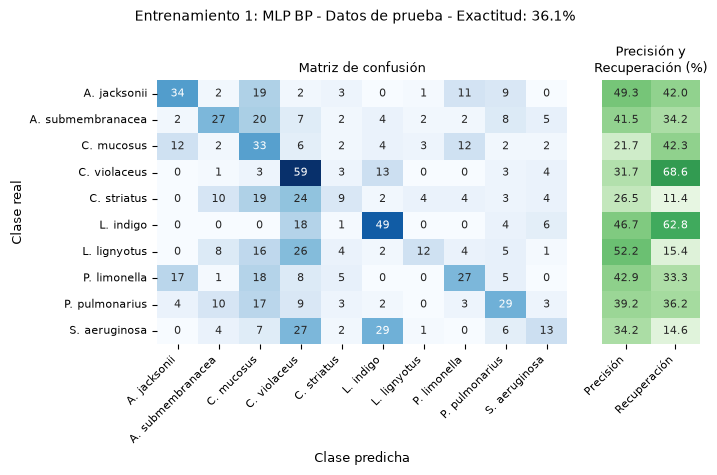

In [17]:
evaluar(mlp, ds_prueba, "Entrenamiento 1: MLP BP - Datos de prueba", "mc_mlp_prueba")

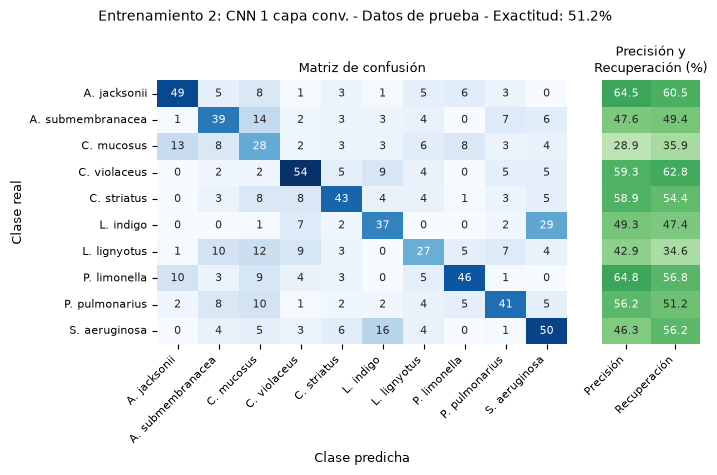

In [18]:
evaluar(cnn1, ds_prueba, "Entrenamiento 2: CNN 1 capa conv. - Datos de prueba", "mc_cnn1_prueba")

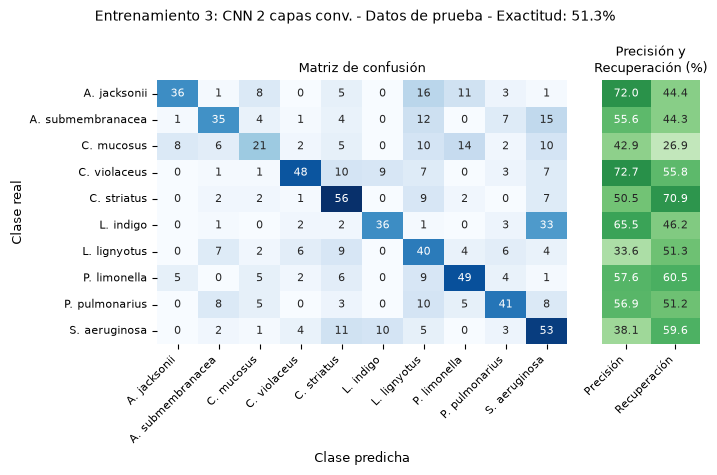

In [19]:
evaluar(cnn2, ds_prueba, "Entrenamiento 3: CNN 2 capas conv. - Datos de prueba", "mc_cnn2_prueba")

In [20]:
pd.DataFrame({nombre: resumen(modelo, ds_prueba) for nombre, modelo in modelos.items()}).T.round(3)

,exactitud,f1_macro
MLP BP,0.361,0.344
CNN 1 capa conv.,0.512,0.512
CNN 2 capas conv.,0.513,0.514


## 10. Exportación

Se guarda un resumen numérico de los resultados y se comprimen los conjuntos de datos y las figuras para publicarlos en el repositorio.

In [21]:
import json

resumen_final = {
    "imagenes": len(df),
    "clases": int(df.clase.nunique()),
    "imagenes_por_clase": df.clase.value_counts().to_dict(),
    "division": {nombre: len(d) for nombre, d in conjuntos.items()},
    "clases_elegidas": CLASES,
    "parametros": {nombre: int(m.count_params()) for nombre, m in modelos.items()},
    "historias": {nombre: {k: [float(x) for x in v] for k, v in h.items()} for nombre, h in historias.items()},
    "comparacion_validacion": comparacion.astype(float).round(4).to_dict(),
    "modelo_elegido": modelo_elegido,
    "prueba": {nombre: {k: float(v) for k, v in resumen(m, ds_prueba).items()} for nombre, m in modelos.items()},
}
with open(f"{DIR_RESULTADOS}/resumen.json", "w", encoding="utf-8") as f:
    json.dump(resumen_final, f, ensure_ascii=False, indent=1)
shutil.make_archive(DIR_DATOS, "zip", DIR_DATOS)
shutil.make_archive(DIR_RESULTADOS, "zip", DIR_RESULTADOS)

'/root/tp2/run/resultados.zip'

Se agregan al resumen la matriz de confusión y la precisión, recuperación y F1 de cada clase, sobre entrenamiento y prueba, para analizar los resultados en el informe.

In [22]:
from sklearn.metrics import classification_report

detalle = {}
for nombre, m in modelos.items():
    detalle[nombre] = {}
    for conjunto, ds in {"entrenamiento": ds_entrenamiento, "prueba": ds_prueba}.items():
        y_real, y_pred = predecir(m, ds)
        detalle[nombre][conjunto] = {
            "matriz": confusion_matrix(y_real, y_pred, labels=range(NUM_CLASES)).tolist(),
            "por_clase": classification_report(y_real, y_pred, labels=range(NUM_CLASES), target_names=CLASES,
                                                output_dict=True, zero_division=0),
        }
resumen_final["detalle"] = detalle
with open(f"{DIR_RESULTADOS}/resumen.json", "w", encoding="utf-8") as f:
    json.dump(resumen_final, f, ensure_ascii=False, indent=1, default=float)
shutil.make_archive(DIR_RESULTADOS, "zip", DIR_RESULTADOS)

'/root/tp2/run/resultados.zip'